# Customer segmentation: clustering
Rebuilds the RFM table from the raw workbook (the cleaning and RFM decisions are explained in
`eda.ipynb`), then scales, clusters, and profiles it.

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

DATA_PATH = "../data/online_retail_II.xlsx"

sheets = pd.read_excel(DATA_PATH, sheet_name=None, engine="openpyxl")
list(sheets.keys())

['Year 2009-2010', 'Year 2010-2011']

In [2]:
# Last timestamp in 2009-2010. The 2010-2011 sheet repeats everything up to here,
# so only rows strictly after it are new.
OVERLAP_CUTOFF = sheets["Year 2009-2010"]["InvoiceDate"].max()

early = sheets["Year 2009-2010"]
late_new_rows = sheets["Year 2010-2011"][sheets["Year 2010-2011"]["InvoiceDate"] > OVERLAP_CUTOFF]

df = pd.concat([early, late_new_rows], ignore_index=True)

print(df.shape)
print(df.duplicated().sum())

(1044848, 8)
11812


In [3]:
print(df["Invoice"].map(type).value_counts())

df["Invoice"] = df["Invoice"].astype(str)

print(df["Invoice"].map(type).value_counts())

Invoice
<class 'int'>    1025677
<class 'str'>      19171
Name: count, dtype: int64
Invoice
<class 'str'>    1044848
Name: count, dtype: int64


In [4]:
# Cancellations and non-product codes are kept on purpose: the RFM build in Step 2 uses
# cancellations for Monetary only, and the non-product rows are -0.42% of value.
df_clean = df[df["Customer ID"].notna() & (df["Price"] > 0)].copy()

# Customer ID was a float only because of the nulls
df_clean["Customer ID"] = df_clean["Customer ID"].astype(int)

print(df_clean.shape)
print(df_clean["Customer ID"].nunique())

(809491, 8)
5939


In [5]:
SNAPSHOT_DATE = df_clean["InvoiceDate"].max() + pd.Timedelta(days=1)

purchases = df_clean[~df_clean["Invoice"].str.startswith("C")]

last_purchase = purchases.groupby("Customer ID")["InvoiceDate"].max()
recency = (SNAPSHOT_DATE - last_purchase).dt.days
recency.name = "Recency"

frequency = purchases.groupby("Customer ID")["Invoice"].nunique()
frequency.name = "Frequency"

line_total = df_clean["Quantity"] * df_clean["Price"]
monetary = line_total.groupby(df_clean["Customer ID"]).sum()
monetary.name = "Monetary"

rfm = pd.concat([recency, frequency, monetary], axis=1)

rfm = rfm.dropna()
rfm[["Recency", "Frequency"]] = rfm[["Recency", "Frequency"]].astype(int)

print(rfm.shape)

(5878, 3)


## Preprocessing: clip, log, scale
Decision from `eda.ipynb`: clip Monetary at 0, log1p on the skewed columns, then
StandardScaler. Done on a copy so `rfm` stays the raw table.

In [6]:
import numpy as np
from sklearn.cluster import KMeans
from sklearn.decomposition import PCA
from sklearn.metrics import silhouette_score
from sklearn.preprocessing import StandardScaler

RANDOM_STATE = 42
K_RANGE = range(2, 11)
N_INIT = 10

### Transform

In [7]:
# Recency is left as is: its skew is 0.89, mild next to Frequency (12.6) and Monetary (26.7)
LOG_COLUMNS = ["Frequency", "Monetary"]

rfm_model = rfm.copy()
# log1p is undefined at or below -1, so the 35 customers with Monetary <= 0 are set to zero
rfm_model["Monetary"] = rfm_model["Monetary"].clip(lower=0)
rfm_model[LOG_COLUMNS] = np.log1p(rfm_model[LOG_COLUMNS])

print("NaN:", rfm_model.isna().sum().sum(), "| inf:", np.isinf(rfm_model).sum().sum())
print(rfm_model.skew())

NaN: 0 | inf: 0
Recency      0.887198
Frequency    1.001471
Monetary    -0.377878
dtype: float64


### Scale

In [8]:
scaler = StandardScaler()
# fit_transform returns a NumPy array, so rebuild the DataFrame to keep the Customer ID index
rfm_scaled = pd.DataFrame(
    scaler.fit_transform(rfm_model),
    index=rfm_model.index,
    columns=rfm_model.columns,
)

print(rfm_scaled.mean().round(6))
print(rfm_scaled.std().round(3))
print(rfm_scaled.shape, "| index matches rfm:", rfm_scaled.index.equals(rfm.index))

Recency     -0.0
Frequency    0.0
Monetary     0.0
dtype: float64
Recency      1.0
Frequency    1.0
Monetary     1.0
dtype: float64
(5878, 3) | index matches rfm: True


### Choosing k
Elbow (inertia) and silhouette over k = 2 to 10. Neither is conclusive alone

In [9]:
inertias = []
silhouettes = []

for k in K_RANGE:
    model = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT)
    labels = model.fit_predict(rfm_scaled)
    inertias.append(model.inertia_)
    silhouettes.append(silhouette_score(rfm_scaled, labels))

k_scores = pd.DataFrame(
    {"inertia": inertias, "silhouette": silhouettes},
    index=pd.Index(K_RANGE, name="k"),
)
print(k_scores)

        inertia  silhouette
k                          
2   9103.106002    0.414351
3   5980.815195    0.397475
4   4789.387603    0.356465
5   3933.529545    0.357290
6   3392.667418    0.369045
7   2874.815725    0.350272
8   2530.920075    0.341228
9   2286.950544    0.321805
10  2129.237357    0.314369


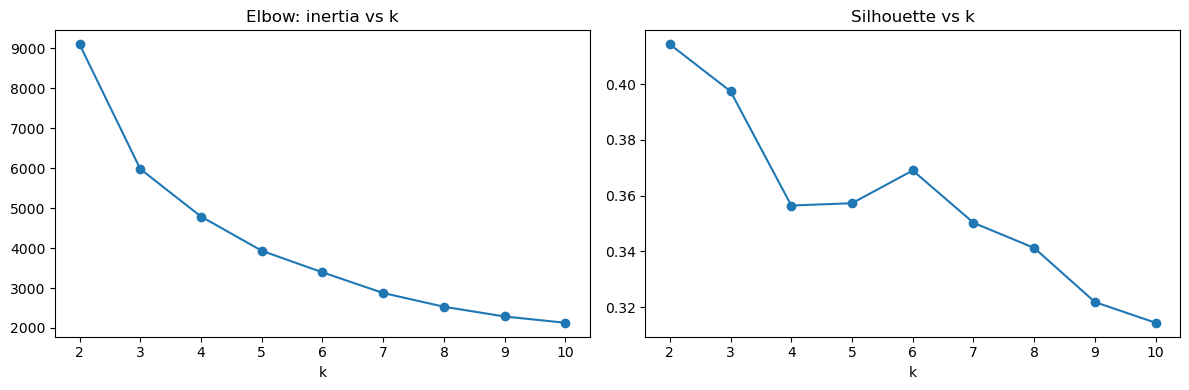

In [10]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
k_scores["inertia"].plot(marker="o", ax=axes[0], title="Elbow: inertia vs k")
k_scores["silhouette"].plot(marker="o", ax=axes[1], title="Silhouette vs k")
for ax in axes:
    ax.set_xticks(list(K_RANGE))
plt.tight_layout()
plt.savefig("../images/choosing_k.png", dpi=150)
plt.show()

In [11]:
# Set from the plots above; add or remove values as you narrow down
CANDIDATE_KS = [3, 4, 5]
is_clipped = (rfm["Monetary"] <= 0).to_numpy()

for k in CANDIDATE_KS:
    labels = KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(rfm_scaled)
    print(f"k = {k}")
    print("  cluster sizes:         ", pd.Series(labels).value_counts().sort_index().to_dict())
    print("  clipped (35) by cluster:", pd.Series(labels[is_clipped]).value_counts().sort_index().to_dict())

k = 3
  cluster sizes:          {0: 1847, 1: 2379, 2: 1652}
  clipped (35) by cluster: {0: 33, 1: 2}
k = 4
  cluster sizes:          {0: 1642, 1: 946, 2: 1399, 3: 1891}
  clipped (35) by cluster: {0: 27, 2: 8}
k = 5
  cluster sizes:          {0: 1687, 1: 1044, 2: 1412, 3: 909, 4: 826}
  clipped (35) by cluster: {1: 29, 2: 6}


In [14]:
labels_by_k = {
    k: pd.Series(KMeans(n_clusters=k, random_state=RANDOM_STATE, n_init=N_INIT).fit_predict(rfm_scaled), index=rfm.index)
    for k in (3, 4, 5)
}

print("k = 3 (rows) vs k = 4 (columns)")
print(pd.crosstab(labels_by_k[3], labels_by_k[4]))
print("\nk = 4 (rows) vs k = 5 (columns)")
print(pd.crosstab(labels_by_k[4], labels_by_k[5]))

k = 3 (rows) vs k = 4 (columns)
col_0     0    1     2     3
row_0                       
0      1638    0   151    58
1         4    0  1248  1127
2         0  946     0   706

k = 4 (rows) vs k = 5 (columns)
col_0     0     1     2    3    4
row_0                            
0         0  1031    11  600    0
1       120     0     0    0  826
2         0    13  1320   66    0
3      1567     0    81  243    0


### Why this k?

**Evidence:** Silhouette is highest at k = 2 (0.414) but k = 2 only splits active from
inactive customers, which is too coarse to target. It falls to 0.397 at k = 3 and about 0.356
at k = 4 and 5. The elbow is gradual: inertia falls 34% from k = 2 to 3, then 20% and 18% for
the next two, with no sharp corner. At k = 3 to 5 the cluster sizes are balanced (smallest 826
customers) and the 35 clipped customers land inside large clusters instead of forming their
own. At k = 6 a 52-customer cluster with median Monetary of 0 appears, and all 35 clipped
customers are in it, so I did not go that high.

**Choice:** k = 4.

**Why:** At k = 3 the middle cluster (2,379) mixes recent low-spend customers with mid-value
regulars. At k = 4 it splits into recent low-spend customers (1,248; median Recency 71,
Frequency 2, £365) and mid-value regulars (1,127, joined by 706 customers from the k = 3
best cluster; median 57 days, Frequency 5, £1,526). The best customers form a cluster of 946
holding 70% of spend. Silhouette is flat between k = 4 and 5 (0.356 vs 0.357), so there is
no separation case for a fifth cluster. I kept the simpler segmentation.

**Limitation:** k = 5 would separate lapsed former regulars (392 days, Frequency 3, £847) from
one-time buyers who never returned, a natural win-back group. At k = 4 most of them (600 of
909) share a cluster with the one-time buyers, so win-back targeting would need further
analysis.

## Final Model

In [12]:
CHOSEN_K = 4

final_model = KMeans(n_clusters=CHOSEN_K, random_state=RANDOM_STATE, n_init=N_INIT)

# Raw units, so the profile in the next section means something to a marketer
rfm_clustered = rfm.copy()
rfm_clustered["Cluster"] = final_model.fit_predict(rfm_scaled)

print(f"Hyperparameters: k = {CHOSEN_K}, n_init = {N_INIT}, random_state = {RANDOM_STATE}")
print(rfm_clustered["Cluster"].value_counts().sort_index())

Hyperparameters: k = 4, n_init = 10, random_state = 42
Cluster
0    1642
1     946
2    1399
3    1891
Name: count, dtype: int64


### Stability across seeds

In [13]:
from sklearn.metrics import adjusted_rand_score

STABILITY_SEEDS = [1, 7, 123, 2024, 99]

for seed in STABILITY_SEEDS:
    labels = KMeans(n_clusters=CHOSEN_K, random_state=seed, n_init=N_INIT).fit_predict(rfm_scaled)
    ari = adjusted_rand_score(rfm_clustered["Cluster"], labels)
    print(f"seed {seed:>4}: ARI vs main = {ari:.3f} | sorted sizes {sorted(np.bincount(labels).tolist())}")

seed    1: ARI vs main = 0.926 | sorted sizes [888, 1481, 1658, 1851]
seed    7: ARI vs main = 0.945 | sorted sizes [898, 1465, 1646, 1869]
seed  123: ARI vs main = 0.992 | sorted sizes [937, 1405, 1644, 1892]
seed 2024: ARI vs main = 0.996 | sorted sizes [947, 1394, 1647, 1890]
seed   99: ARI vs main = 0.917 | sorted sizes [877, 1491, 1657, 1853]


### Observations: final model

**Findings:** The final K-Means model (k = 4, n_init = 10, random_state = 42) splits the 5,878
customers into clusters of 1,642, 946, 1,399 and 1,891. Refitting with five other seeds gives
an adjusted Rand index of 0.92 to 1.00 against it (mean about 0.96), so the four-cluster
structure is stable. The smallest cluster varies between 877 and 947 customers depending on
the seed.

**Decisions:** Hyperparameters are fixed and logged (k = 4, n_init = 10, seed 42). The model is
fitted on all customers with no train/test split, since this is unsupervised. Labels are
attached to a copy of the raw `rfm` (`rfm_clustered`) so the profile uses original units.

**Limitations:** Cluster boundaries are soft: customers near a boundary move between
neighbouring clusters from seed to seed. The labels 0 to 3 are arbitrary and can change
between fits, so clusters are described by their R/F/M values, not their numbers. The profile
and personas follow in the next section.